# PieceSpice — Notebook 04a: Simple Switching Subset (M4, Tier-2 scope)

**Bench:** gate pulse at **50 kHz / 50 % duty**, resistive load sized
for **1 A** on-state current. The vendor model and our synthesized
Tier-2 CPWL macromodel are simulated under **identical** conditions;
their waveforms and extracted metrics are compared.

**Scope (honest Tier-2 subset):** this M4 bench is a resistive-load
switching stress, not the clamped-inductive DPT validation bench. Tier-3
v1 does not converge here; Tier-3 SIMPLIS, UROM C0/ANN and Tier-4/T4_ANN
are specified against the DPT bench (notebook 03 / 05). Their recorded DPT
fidelity is read from JSON in the final section and is **not** re-simulated
here. No T3/T4 trace is fabricated.

- Vendor: set `VENDOR` in the setup cell (any configured vendor)
- Core solvers: `simulation/testbenches/simple_switching.py` +
  `metrics/fitness.py` — this notebook only calls and plots.


In [1]:
# PieceSpice — Notebook 04a: Simple Switching Subset (M4, Tier-2 scope)
# 50 kHz / 50 % duty, resistive load sized for the YAML target current.
# All computation lives in library modules; this notebook only calls & plots.

import sys, os
from pathlib import Path
REPO_ROOT = Path.cwd()
if REPO_ROOT.name == 'notebooks':
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT))
os.chdir(REPO_ROOT)

VENDOR = "epc2216"          # change to any configured vendor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

from common.plotting import setup_style

from simulation.testbenches.simple_switching import run_simple_switching
from metrics.fitness import compare_switching_fitness
from pipeline.fitting import fit_pwl_model

cfg = yaml.safe_load(
    Path(f"config/inputs/{VENDOR}.yaml").read_text(encoding="utf-8"))

# --- switching conditions (subset defaults; override here if needed) ---
VBUS = float(cfg["conditions"].get("Vbus",
            cfg["conditions"].get("Vds_fixed", 10.0)))
VGS_ON = float(cfg["conditions"]["Vgs_fixed"])
I_LOAD = 1.0                # A - user spec: total system current 1 A
TEMP = float(cfg["conditions"].get("temperature", 25.0))
# Both models are live-simulated here, so the drive is self-consistent. When
# comparing against a SAVED golden CSV, recover its conditions with
# infer_drive_conditions() instead of using today's YAML.

print(f"Vendor : {VENDOR} ({cfg['vendor']})")
print(f"Vbus   : {VBUS} V | Vgs_on: {VGS_ON} V | I_load: {I_LOAD} A")

# plotting helper (house rule: legend EAST outside)
def _ax_legend_east(ax):
    leg = ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
    return leg

setup_style()


Vendor : epc2216 (epc)
Vbus   : 12.0 V | Vgs_on: 5.0 V | I_load: 1.0 A


---
## 1 · Run Both Models

In [2]:
# --- Run both models through the identical testbench ---
REBUILD_TIER2 = False   # set True to force re-fitting via notebook 02 logic

t2_path = Path("reports/models") / f"{VENDOR}_PIECESPICE_T2.lib"

if REBUILD_TIER2 or not t2_path.exists():
    if not t2_path.exists():
        raise FileNotFoundError(
            f"Tier-2 model for '{VENDOR}' not found at {t2_path}.\n"
            "Run notebooks/02_piecewise_approximation.ipynb first to fit and "
            "synthesize it (or set REBUILD_TIER2 = True in this cell).")
    tier2_lib = fit_pwl_model(VENDOR)
else:
    tier2_lib = t2_path
print("Tier-2 lib:", tier2_lib)

run_golden = run_simple_switching(
    Path(cfg["library"]), cfg["subcircuit"], cfg["pins"]["pin_order"],
    vbus=VBUS, vgs_on=VGS_ON, i_load_target=I_LOAD, temperature=TEMP)

run_tier2 = run_simple_switching(
    Path(tier2_lib), tier2_lib.stem, ["drain", "gate", "source"],
    vbus=VBUS, vgs_on=VGS_ON, i_load_target=I_LOAD, temperature=TEMP)

print("golden :", len(run_golden.time), "points")
print("tier-2 :", len(run_tier2.time), "points")

Tier-2 lib: reports\models\epc2216_PIECESPICE_T2.lib


golden : 34448 points
tier-2 : 30207 points


---
## 2 · Full Switching Waveform — 3 Cycles Overlay

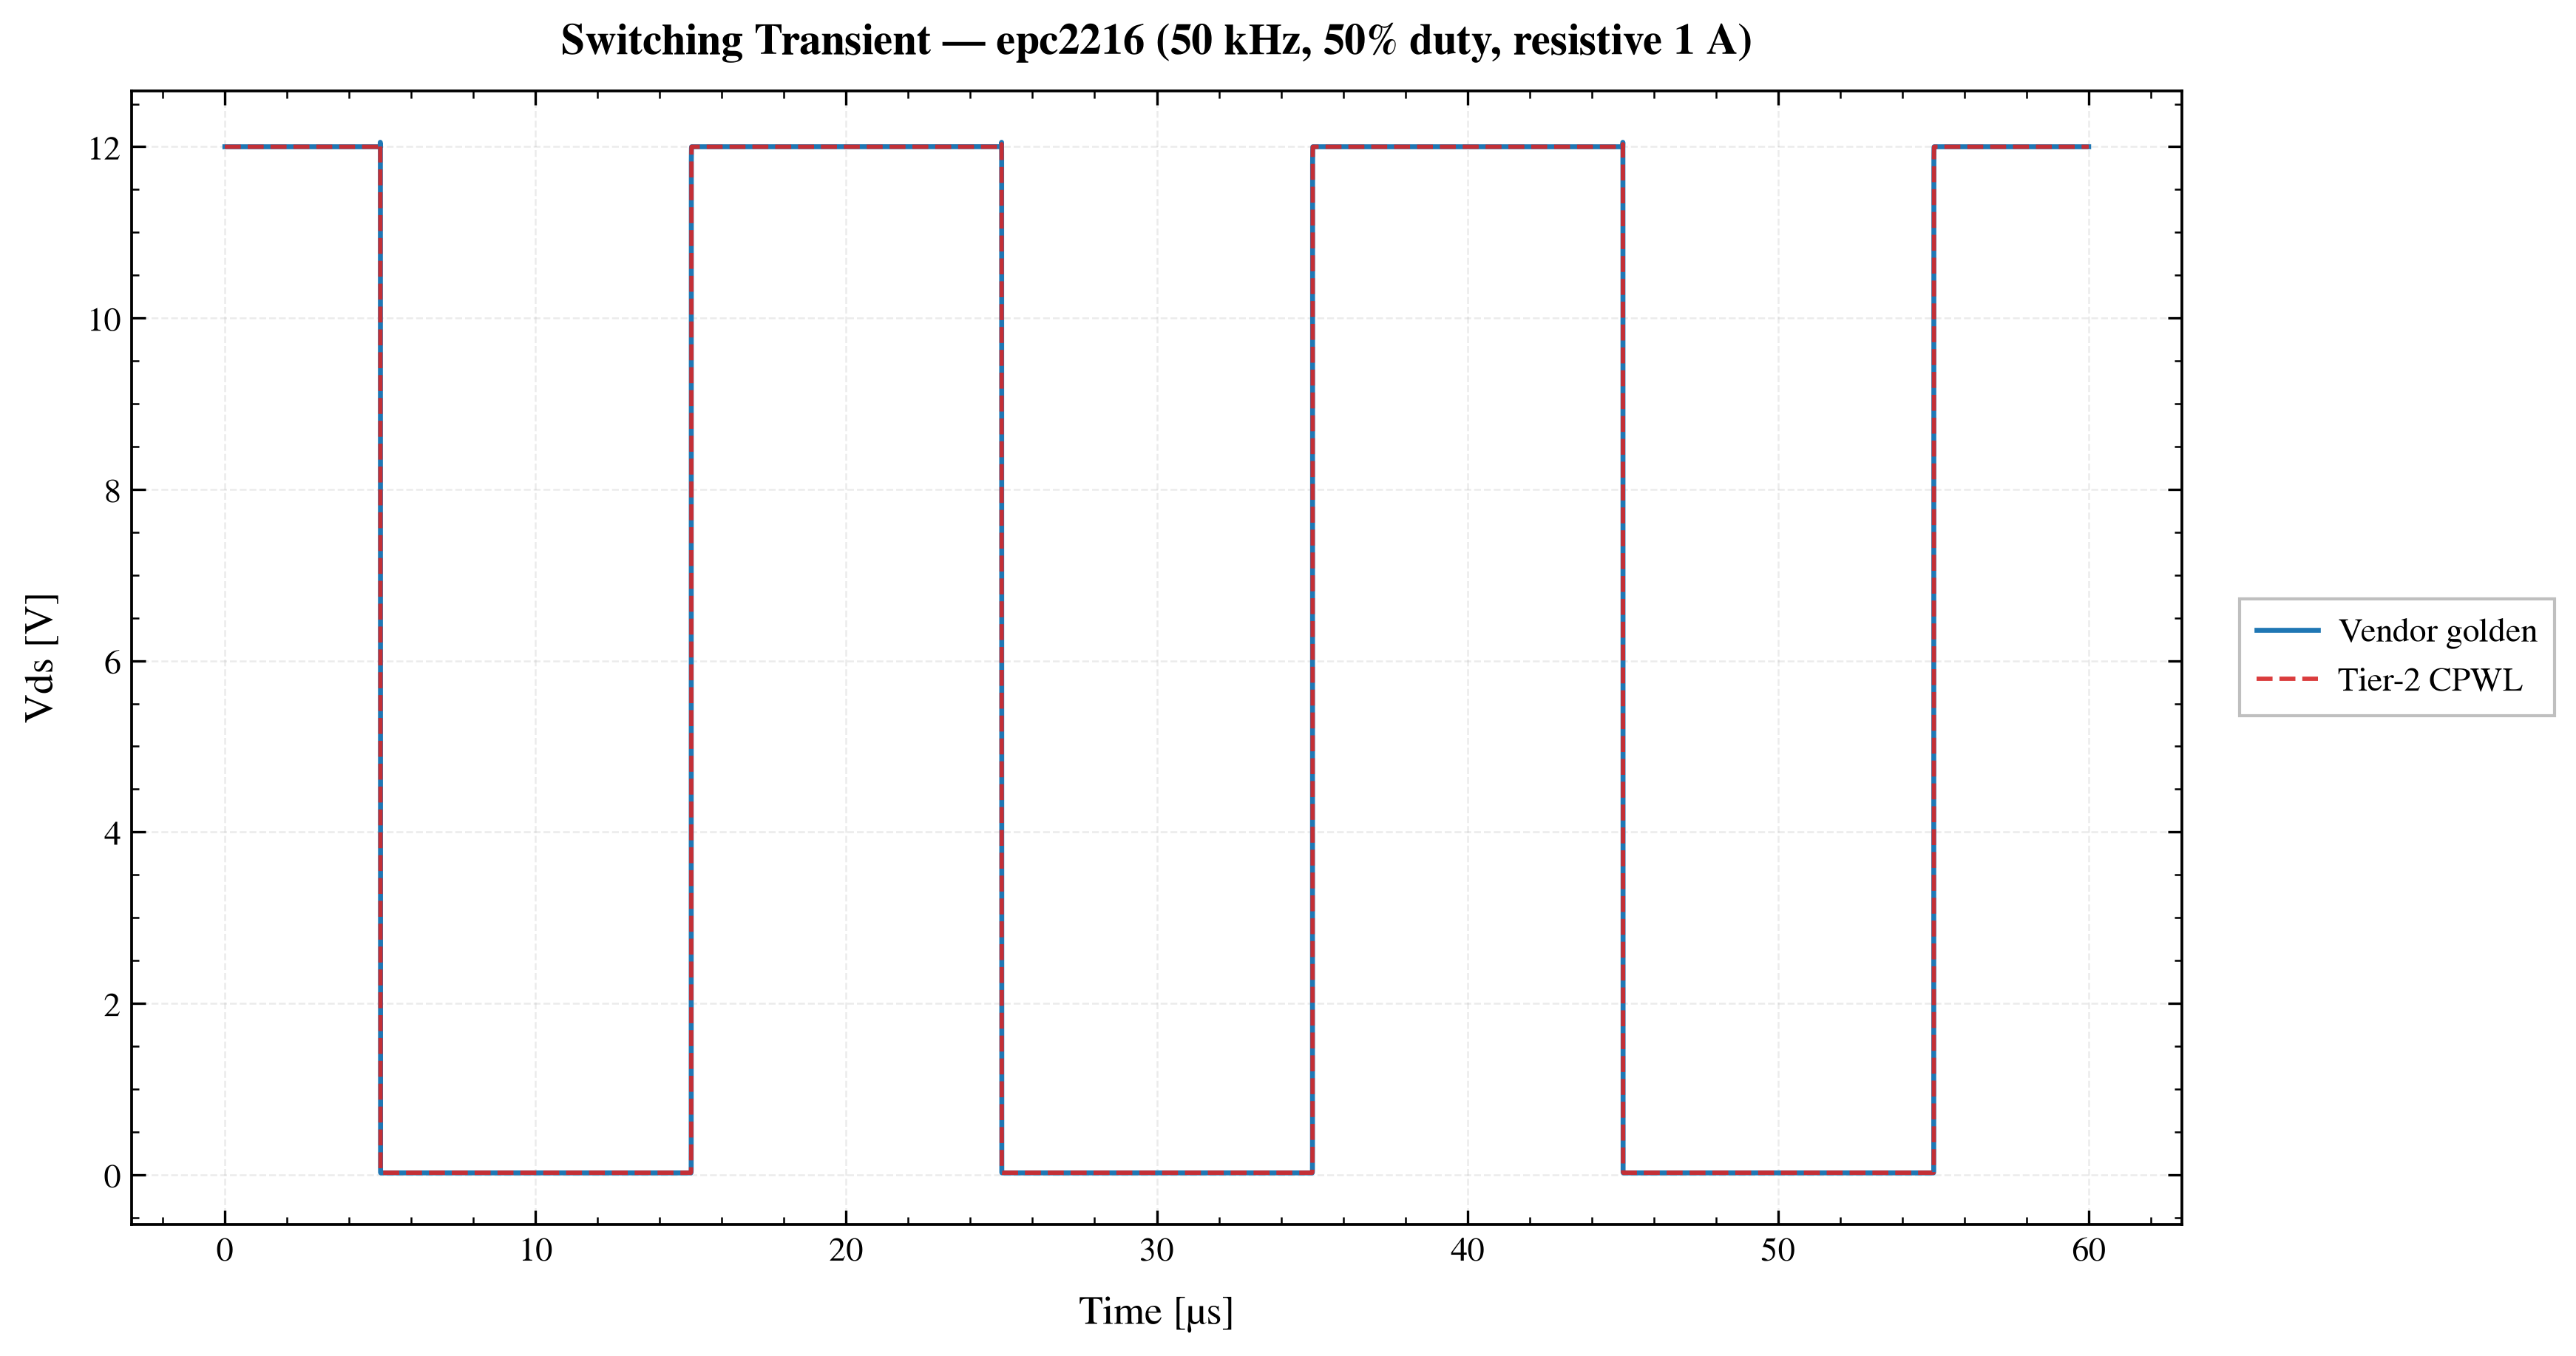

In [3]:
# --- Comparison plot 1: full run — 3 steady switching cycles ---
fig, ax = plt.subplots(figsize=(11.5, 6.0), layout="constrained")
ax.plot(run_golden.time * 1e6, run_golden.v_ds, lw=1.6,
        color="tab:blue", label="Vendor golden")
ax.plot(run_tier2.time * 1e6, run_tier2.v_ds, lw=1.4, ls="--",
        color="tab:red", alpha=0.9, label="Tier-2 CPWL")
ax.set_xlabel("Time [µs]")
ax.set_ylabel("Vds [V]")
ax.set_title(f"Switching Transient — {VENDOR} "
             f"(50 kHz, 50% duty, resistive {I_LOAD:.0f} A)")
ax.grid(True, alpha=0.25)
_ax_legend_east(ax)
plt.show()


---
## 3 · Zoomed View — One Cycle (Turn-On / Turn-Off Edges)

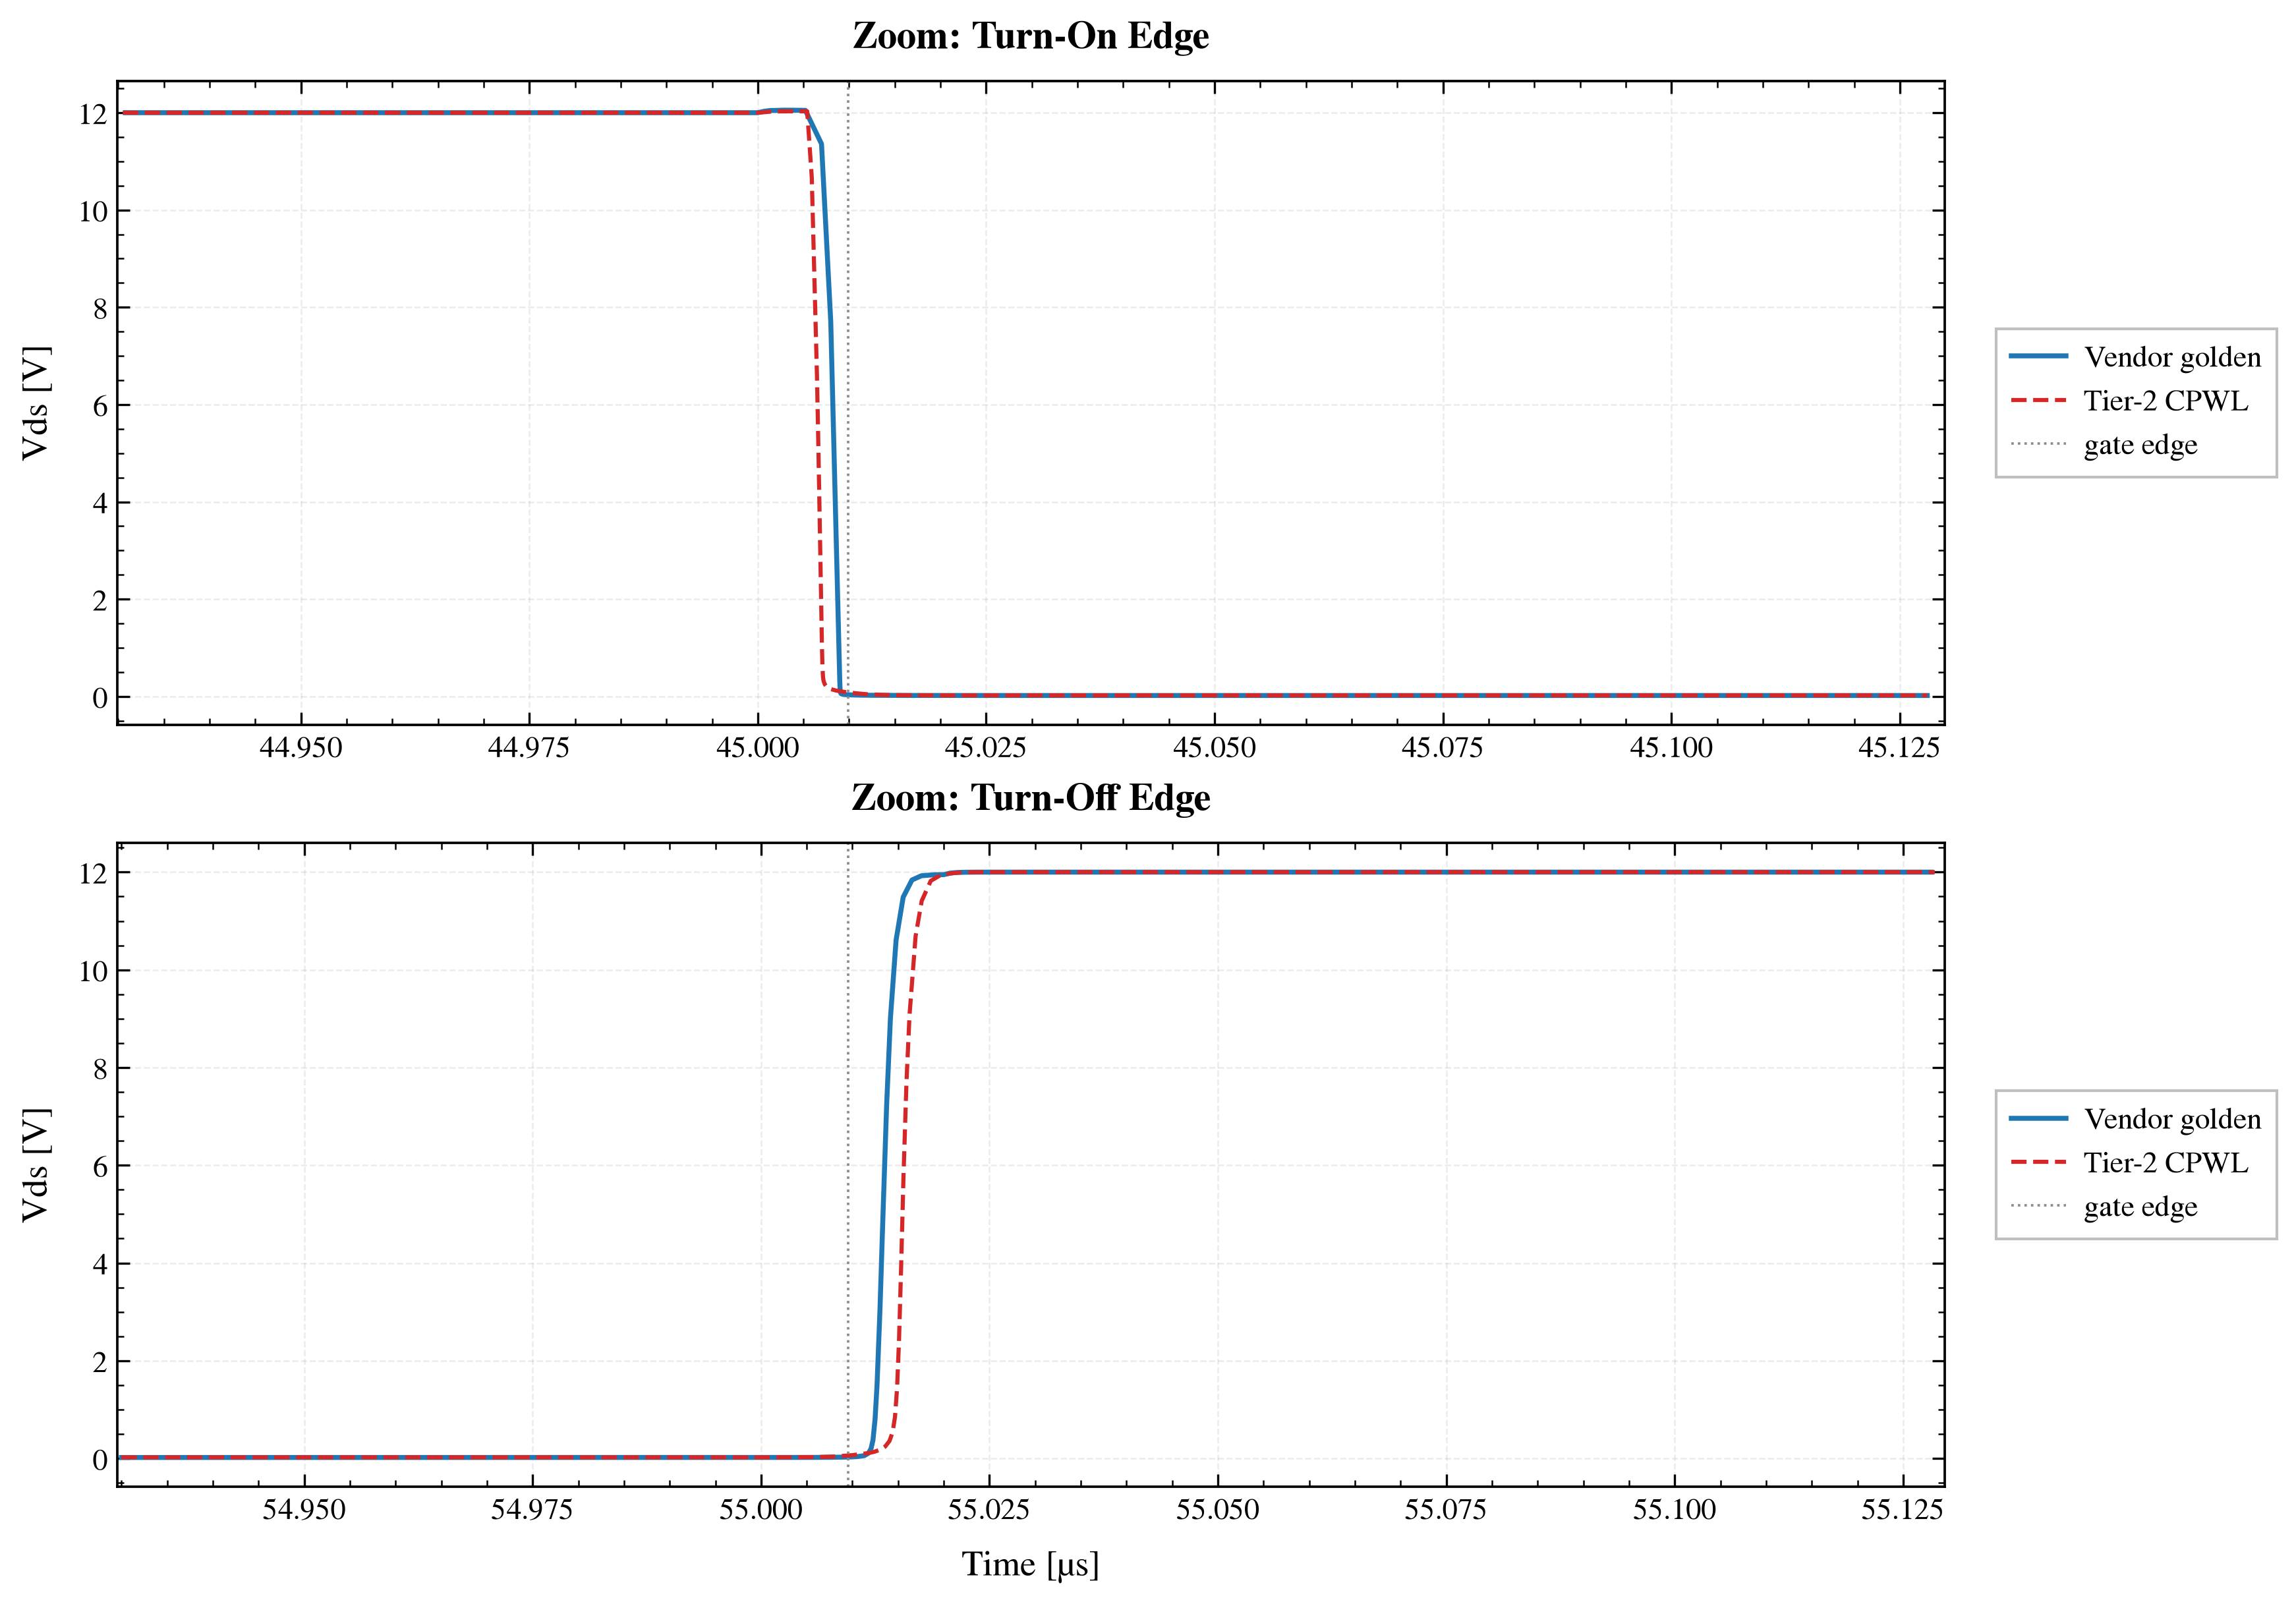

In [4]:
# --- Comparison plot 2: zoomed on the actual turn-on and turn-off edges ---
# The gate pulse starts at 5 us, so the final 20 us cycle (40-60 us) contains
# turn-on at 45 us and turn-off at 54.98 us.  Locate both edges from the
# golden gate trace instead of assuming they sit at the cycle boundaries.
period = 1.0 / 50_000.0
t_end = run_golden.time[-1]
t_lo = t_end - period                      # last full cycle
thr = 0.5 * VGS_ON

last = run_golden.time >= t_lo
tg = run_golden.time[last]
vg = run_golden.v_gs[last]
rising = np.where((vg[:-1] < thr) & (vg[1:] >= thr))[0]
falling = np.where((vg[:-1] >= thr) & (vg[1:] <= thr))[0]
if len(rising) == 0 or len(falling) == 0:
    raise RuntimeError("could not locate a gate edge in the final switching cycle")
on_t = float(tg[rising[0]])
off_t = float(tg[falling[0]])

# 40 ns before / 60 ns after each gate edge: enough to show delay + transition
pad_lo, pad_hi = 0.004 * period, 0.006 * period
on_lo, on_hi = on_t - pad_lo, on_t + pad_hi
off_lo, off_hi = off_t - pad_lo, off_t + pad_hi

def _zoom_mask(run, lo, hi):
    return (run.time >= lo) & (run.time <= hi)

fig, axs = plt.subplots(2, 1, figsize=(11.5, 8.0), sharex=False,
                        layout="constrained")
for ax, (lo, hi), title in (
        (axs[0], (on_lo, on_hi), "Zoom: Turn-On Edge"),
        (axs[1], (off_lo, off_hi), "Zoom: Turn-Off Edge")):
    mg = _zoom_mask(run_golden, lo, hi)
    mt = _zoom_mask(run_tier2, lo, hi)
    ax.plot(run_golden.time[mg] * 1e6, run_golden.v_ds[mg], lw=1.8,
            color="tab:blue", label="Vendor golden")
    ax.plot(run_tier2.time[mt] * 1e6, run_tier2.v_ds[mt], lw=1.5, ls="--",
            color="tab:red", label="Tier-2 CPWL")
    ax.axvline((on_t if title.startswith("Zoom: Turn-On") else off_t) * 1e6,
               color="0.55", lw=0.9, ls=":", label="gate edge")
    ax.set_xlim(lo * 1e6, hi * 1e6)
    ax.set_ylabel("Vds [V]")
    ax.set_title(title)
    ax.grid(True, alpha=0.25)
    _ax_legend_east(ax)
axs[1].set_xlabel("Time [µs]")
plt.show()


---
## 4 · Fitness Metrics

,metric,vendor golden,tier-2 cpwl,error %
0,td_on [ns],5.132,3.864,-24.71
1,tr [ns],1.724,1.144,-33.65
2,td_off [ns],10.601,12.795,+20.69
3,tf [ns],2.347,2.222,-5.33
4,E_on [µJ],0.012,0.012,+2.22
5,E_off [µJ],0.015,0.016,+7.82
6,Vds on-state [mV],19.942,21.962,n/a
7,Id peak [A],0.998,0.998,n/a
8,waveform rel-RMSE [%],n/a,1.053,n/a



VERDICT: FAIL - timing td_on,tr,td_off
Evaluable: True
Waveform rel-RMSE: 1.05%


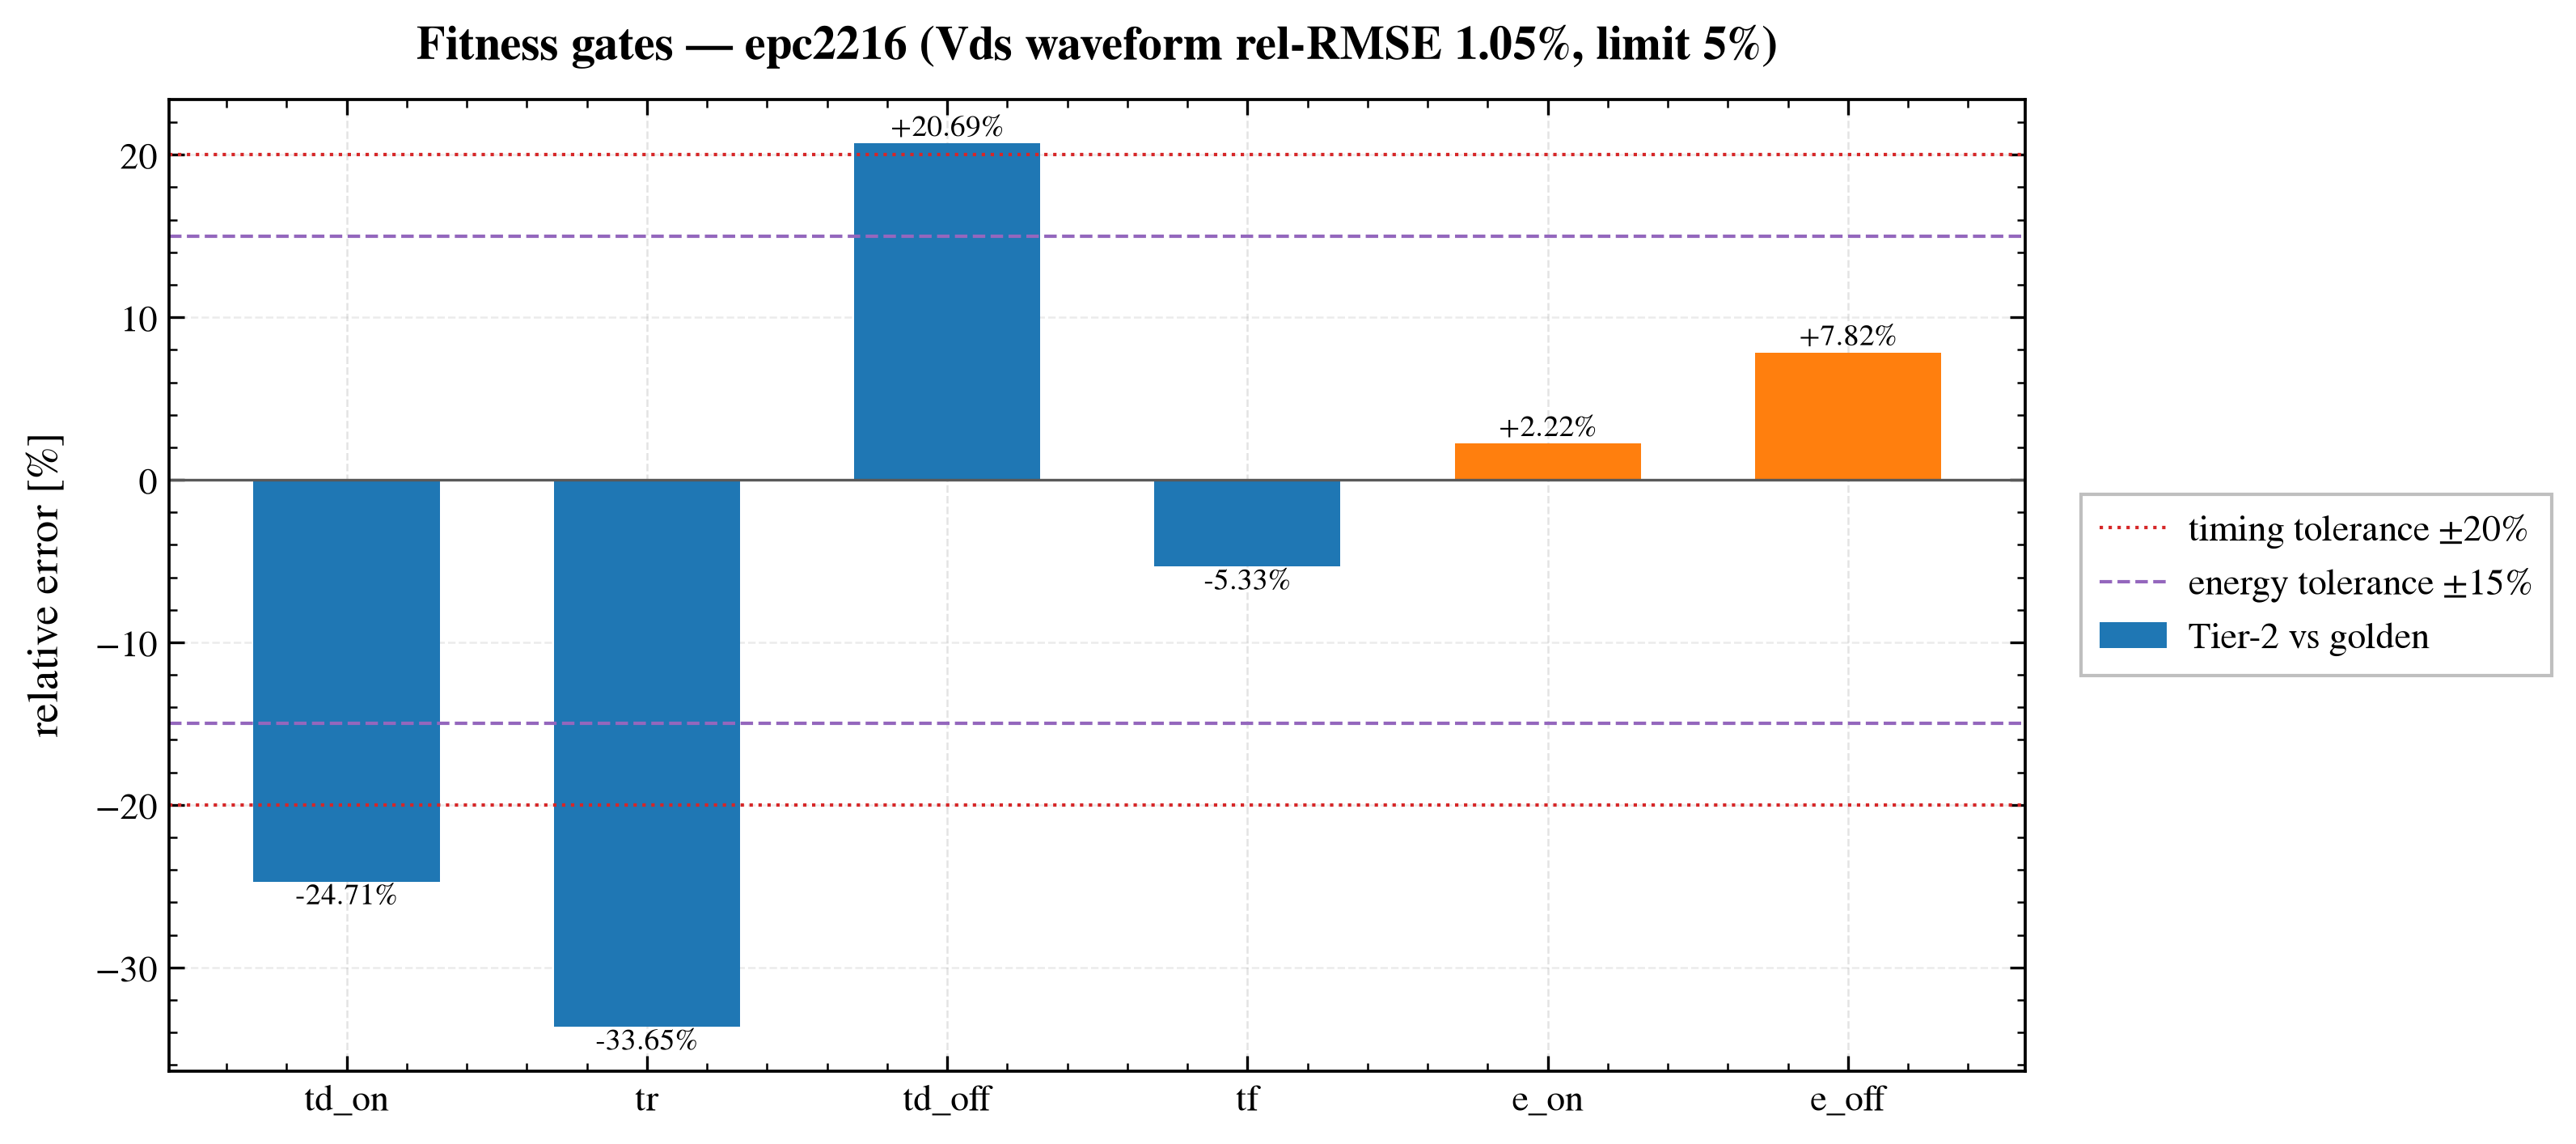

In [5]:
# --- Fitness metrics table ---
fit = compare_switching_fitness(
    vbus=VBUS, vgs_on=VGS_ON, i_load_target=I_LOAD, temperature=TEMP,
    golden_run=run_golden, tier2_run=run_tier2)   # reuse section-1 runs

mg, mt = fit.golden, fit.tier2
df = pd.DataFrame({
    "metric": ["td_on [ns]", "tr [ns]", "td_off [ns]", "tf [ns]",
               "E_on [µJ]", "E_off [µJ]",
               "Vds on-state [mV]", "Id peak [A]",
               "waveform rel-RMSE [%]"],
    "vendor golden": [mg.td_on_ns, mg.tr_ns, mg.td_off_ns, mg.tf_ns,
                      mg.e_on_uj, mg.e_off_uj,
                      mg.vds_on_mean_v * 1e3, mg.i_peak_a, np.nan],
    "tier-2 cpwl": [mt.td_on_ns, mt.tr_ns, mt.td_off_ns, mt.tf_ns,
                    mt.e_on_uj, mt.e_off_uj,
                    mt.vds_on_mean_v * 1e3, mt.i_peak_a,
                    fit.waveform_rel_rmse_pct],
})
errs = (list(fit.timing_rel_err_pct.values())
        + list(fit.energy_rel_err_pct.values())
        + [np.nan, np.nan, np.nan])  # waveform/on-state/peak
df["error %"] = [round(v, 2) if np.isfinite(v) else np.nan for v in errs]

styled = df.style.format({
    "vendor golden": "{:.3f}", "tier-2 cpwl": "{:.3f}",
    "error %": "{:+.2f}"}, na_rep="n/a").background_gradient(
    subset=["error %"], cmap="RdYlGn_r", vmin=-40, vmax=40)
display(styled)
print()
print("VERDICT:", fit.verdict)
print("Evaluable:", fit.evaluable)
print("Waveform rel-RMSE: %.2f%%" % fit.waveform_rel_rmse_pct)

# --- Fitness plot: per-metric relative errors against the stated tolerances ---
labels = list(fit.timing_rel_err_pct) + list(fit.energy_rel_err_pct)
vals = np.array([fit.timing_rel_err_pct[k] for k in fit.timing_rel_err_pct]
                + [fit.energy_rel_err_pct[k] for k in fit.energy_rel_err_pct],
                dtype=float)
colors = ["tab:blue"] * len(fit.timing_rel_err_pct) + \
         ["tab:orange"] * len(fit.energy_rel_err_pct)

fig, ax = plt.subplots(figsize=(10.5, 4.6), layout="constrained")
bars = ax.bar(labels, np.nan_to_num(vals, nan=0.0), color=colors,
              width=0.62, label="Tier-2 vs golden")
for b, v in zip(bars, vals):
    ax.annotate(f"{v:+.2f}%" if np.isfinite(v) else "N/A",
                (b.get_x() + b.get_width() / 2.0, b.get_height()),
                ha="center", va="bottom" if (not np.isfinite(v) or v >= 0) else "top",
                fontsize=9)
ax.axhline(0, color="0.35", lw=0.8)
ax.axhline(20, color="tab:red", ls=":", lw=1.0, label="timing tolerance ±20%")
ax.axhline(-20, color="tab:red", ls=":", lw=1.0)
ax.axhline(15, color="tab:purple", ls="--", lw=1.0, label="energy tolerance ±15%")
ax.axhline(-15, color="tab:purple", ls="--", lw=1.0)
ax.set_ylabel("relative error [%]")
ax.set_title(f"Fitness gates — {VENDOR} "
             f"(Vds waveform rel-RMSE {fit.waveform_rel_rmse_pct:.2f}%, "
             f"limit 5%)")
ax.grid(True, axis="y", alpha=0.25)
_ax_legend_east(ax)
plt.show()


---
## 5 · Recorded DPT Evidence for Other Tiers (not re-simulated)

This M4 resistive bench is the **Tier-2 scope**. Tier-3 v1 does not converge
on it, and the SIMPLIS/UROM/T4/T4_ANN models are validated on the
clamped-inductive DPT bench (notebooks 03 and 05). The numbers below are
read verbatim from `reports/comparison/<vendor>/*.json`; no T3/T4 run is
claimed here and no missing waveform value is filled in.

- **T4** retires the DPT waveform gate by design. Its `energy_comparison` is
  a LUT source self-consistency check (0.00 % by construction), **not** an
  independent validation, so it is not plotted as a waveform result.
- **Tier-2** `dpt_metrics.json` records timing/energy only; its DPT Vds/Id
  waveform RMSE is **not available**. The simple-switching waveform RMSE
  above is a different experiment and is labelled as such.


Recorded DPT fidelity for epc2216 (read from JSON; no re-simulation)


,method,DPT Vds rel-RMSE [%],DPT Id rel-RMSE [%],record / note
0,Tier-2,not available,not available,not recorded in dpt_metrics.json (timing/energy only)
1,Tier-3 v1,2.846,1.469,tier3_validation.json#dpt_run.waveform
2,Tier-3 SIMPLIS,0.467,0.176,tier3_validation_simplis.json#dpt_waveform
3,UROM C0,0.712,0.648,unified_validation.json#dpt_waveform
4,UROM ANN,0.109,0.028,unified_ann_trap-default.json#dpt_waveform
5,T4,not available,not available,waveform gate retired; energy self-consistency only (E_on rel err +0.00% by construction)
6,T4_ANN,0.349,0.240,tier4_validation_ann.json#dpt_waveform


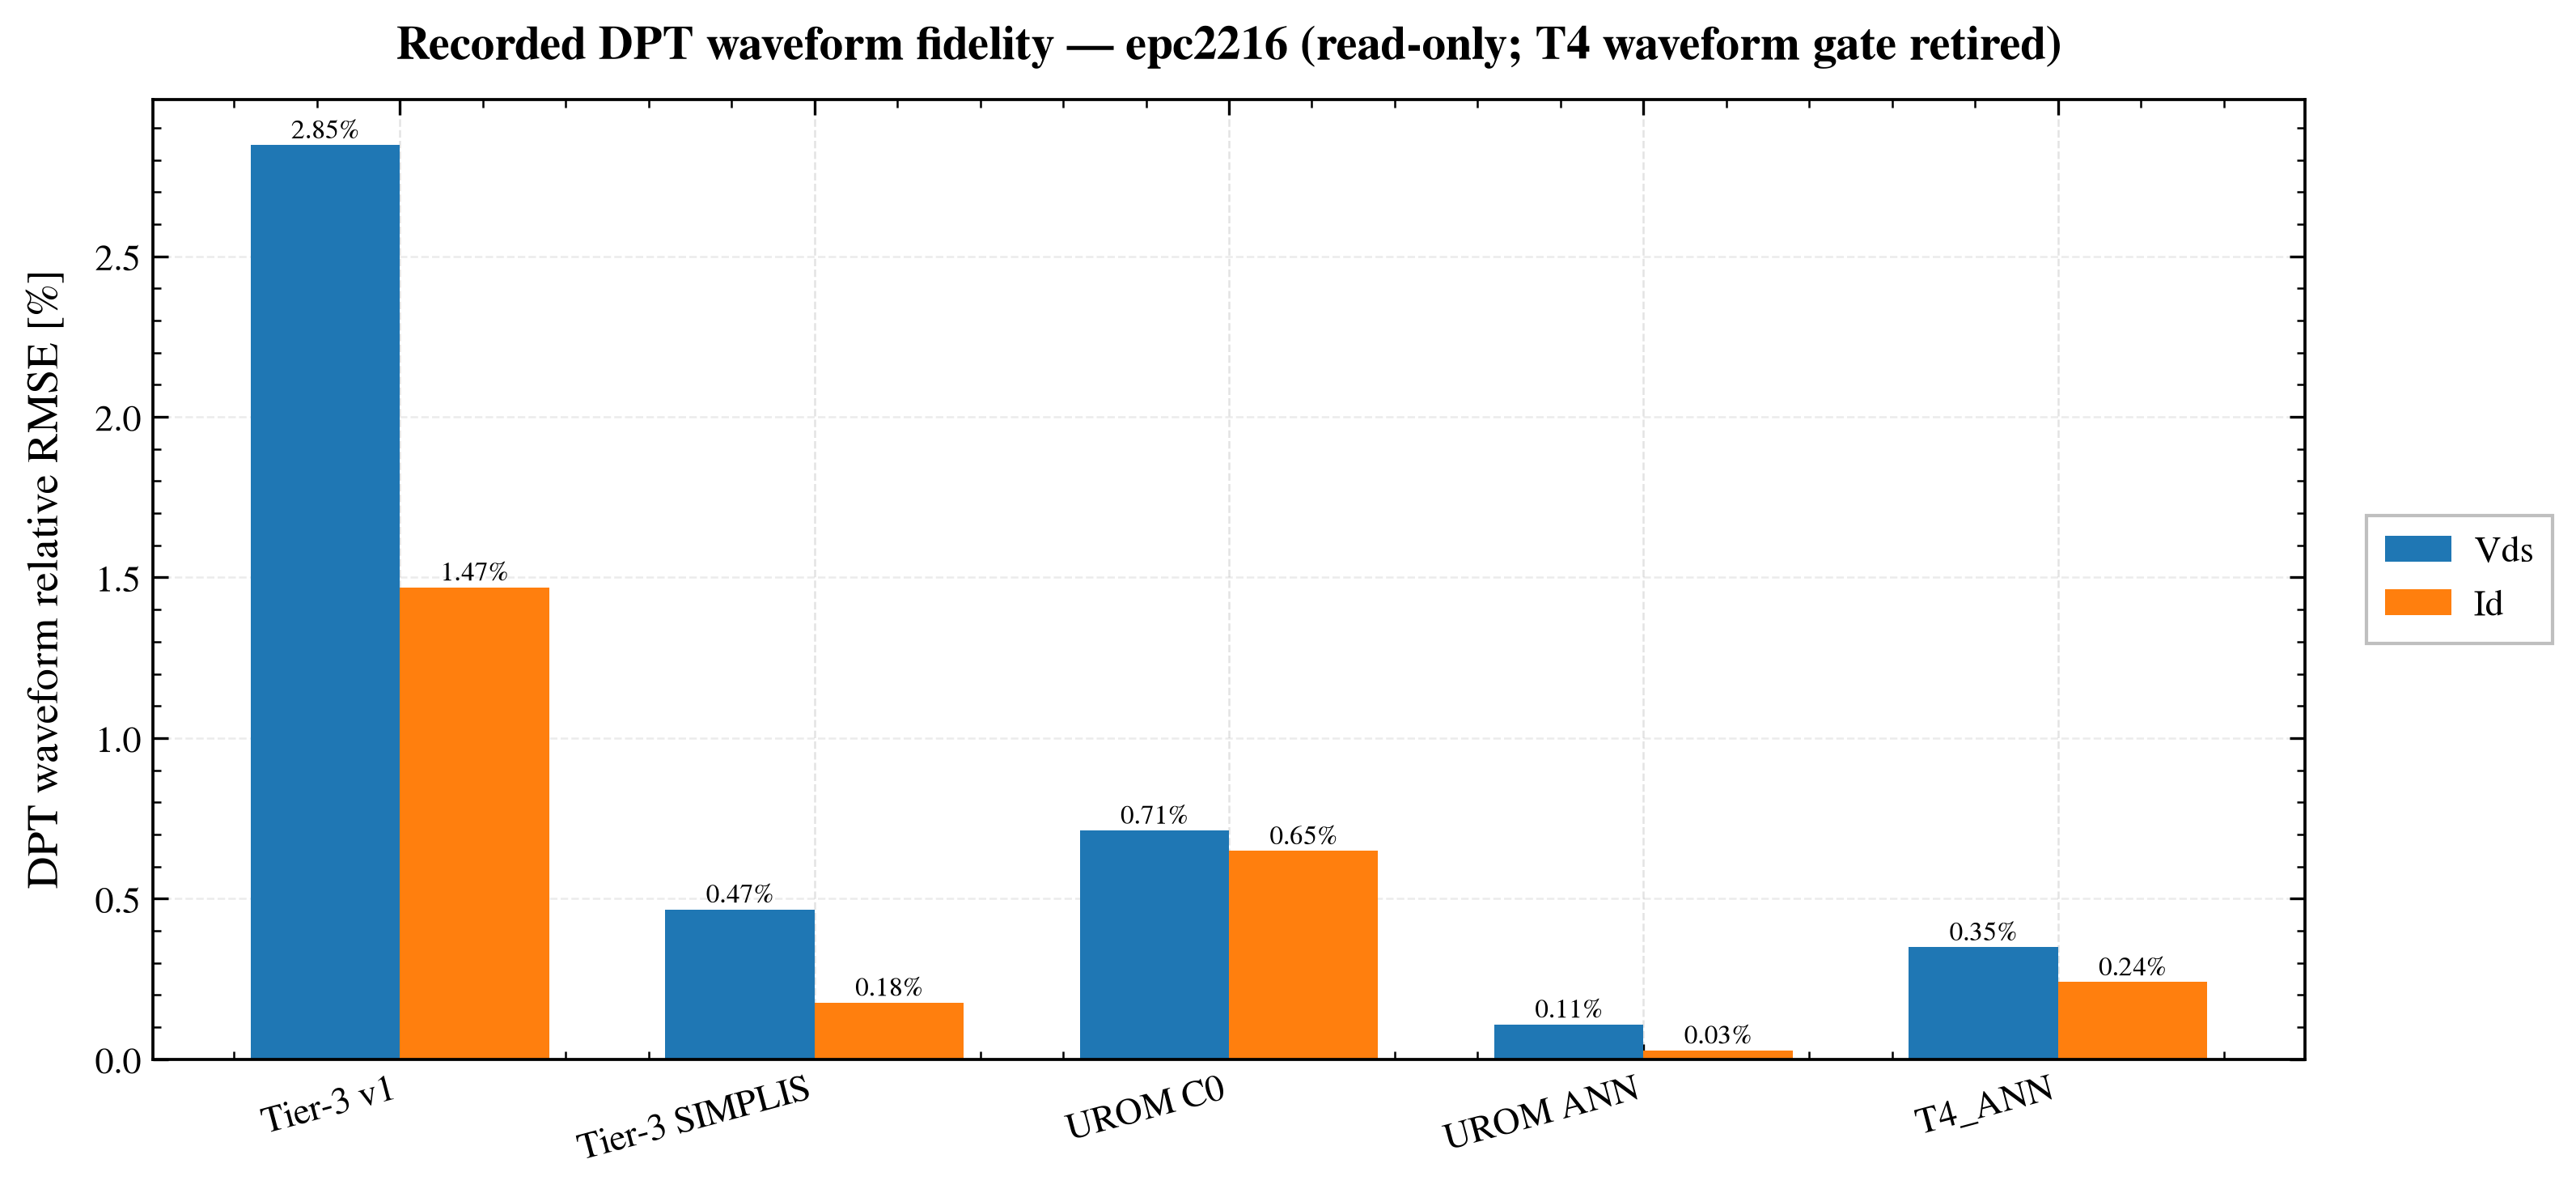

Not plotted (no recorded DPT waveform): Tier-2, T4


In [6]:
# --- Recorded DPT fidelity: read-only JSON evidence for T3/T4 ===============
import json

def _read_json(path):
    p = Path(path)
    return json.loads(p.read_text(encoding="utf-8")) if p.exists() else None

base = Path("reports/comparison") / VENDOR
t3 = _read_json(base / "tier3_validation.json")
t3s = _read_json(base / "tier3_validation_simplis.json")
u0 = _read_json(base / "unified_validation.json")
uann = _read_json(base / "unified_ann_trap-default.json")
t4 = _read_json(base / "tier4_validation.json")
t4ann = _read_json(base / "tier4_validation_ann.json")

def _wave(obj, *keys):
    if obj is None:
        return None, None
    for k in keys:
        obj = obj.get(k) if isinstance(obj, dict) else None
        if obj is None:
            return None, None
    return obj.get("vds_rel_rmse_pct"), obj.get("id_rel_rmse_pct")

def _formatted(v):
    return f"{v:.3f}" if isinstance(v, (int, float)) and np.isfinite(v) else "not available"

rows = []
rows.append(("Tier-2", *_wave(None), "not recorded in dpt_metrics.json (timing/energy only)"))
rows.append(("Tier-3 v1", *_wave(t3, "dpt_run", "waveform"),
             "tier3_validation.json#dpt_run.waveform"))
rows.append(("Tier-3 SIMPLIS", *_wave(t3s, "dpt_waveform"),
             "tier3_validation_simplis.json#dpt_waveform"))
rows.append(("UROM C0", *_wave(u0, "dpt_waveform"),
             "unified_validation.json#dpt_waveform"))
rows.append(("UROM ANN", *_wave(uann, "dpt_waveform"),
             "unified_ann_trap-default.json#dpt_waveform"))
energy_note = "waveform gate retired; energy self-consistency only"
if t4:
    e_on = t4.get("energy_comparison", {}).get("e_on_uj", {})
    if e_on.get("status") == "measured":
        energy_note += f" (E_on rel err {e_on.get('rel_error_pct', 0.0):+.2f}% by construction)"
rows.append(("T4", None, None, energy_note))
rows.append(("T4_ANN", *_wave(t4ann, "dpt_waveform"),
             "tier4_validation_ann.json#dpt_waveform"))

dpt = pd.DataFrame(rows, columns=["method", "DPT Vds rel-RMSE [%]",
                                  "DPT Id rel-RMSE [%]", "record / note"])
print(f"Recorded DPT fidelity for {VENDOR} (read from JSON; no re-simulation)")
display(dpt.style.format({"DPT Vds rel-RMSE [%]": _formatted,
                          "DPT Id rel-RMSE [%]": _formatted}))

# Plot only recorded, independent waveform records.  T4 has no waveform gate.
plot_rows = [(m, v, i) for m, v, i, _ in rows
             if isinstance(v, (int, float)) and isinstance(i, (int, float))]
labels = [r[0] for r in plot_rows]
vds = np.array([r[1] for r in plot_rows])
ids = np.array([r[2] for r in plot_rows])
x = np.arange(len(labels))
w = 0.36

fig, ax = plt.subplots(figsize=(10.5, 4.8), layout="constrained")
b1 = ax.bar(x - w / 2, vds, w, color="tab:blue", label="Vds")
b2 = ax.bar(x + w / 2, ids, w, color="tab:orange", label="Id")
for bars, vals in ((b1, vds), (b2, ids)):
    for b, v in zip(bars, vals):
        ax.annotate(f"{v:.2f}%", (b.get_x() + b.get_width() / 2, b.get_height()),
                    ha="center", va="bottom", fontsize=8)
ax.set_xticks(x, labels, rotation=15, ha="right")
ax.set_ylabel("DPT waveform relative RMSE [%]")
ax.set_title(f"Recorded DPT waveform fidelity — {VENDOR} "
             "(read-only; T4 waveform gate retired)")
ax.grid(True, axis="y", alpha=0.25)
_ax_legend_east(ax)
plt.show()

missing = [m for m, v, i, _ in rows
           if not (isinstance(v, (int, float)) and isinstance(i, (int, float)))]
if missing:
    print("Not plotted (no recorded DPT waveform):", ", ".join(missing))
